# Figure 2 — cell-type clustering and annotation

Single-cell NOMe-HiC of a defined GM12878 + IMR90 mixture, **441 QC-passing cells**.
Each modality is clustered independently, then cell types are assigned by correlating
per-cluster pseudobulk methylation against bulk references.

| Modality | Embedding for clustering | Leiden `n_pc` | resolution | knn_k |
|---|---|---|---|---|
| **HCG methylation** | raw SVD (no Harmony) | 5 | 0.10 | 25 |
| **Hi-C** | hicluster SVD → Harmony | 5 | 0.10 | 25 |
| **GCH accessibility** | top-11547 variable bins → SVD → Harmony | 3 | 0.20 | 25 |

Cell-type annotation (§7): per HCG-cluster pseudobulk, Pearson correlation against
250 kb bulk methylation references, `bulk_methylation_{GM12878,IMR90}.txt.gz` — built
by `data_processing/bulk_others/02_process/03_build_bulk_methylation_bins.py`.

Clustering parameters were selected by sweeps run during development on an earlier
380-cell cohort. Those sweep scripts are not part of this repository; the values they
chose are recorded in §5 and §6.


In [1]:
# §1 Setup
Sys.setenv(RETICULATE_PYTHON = "/projects/b1198/epifluidlab/yoshii/software/conda/envs/scnomehic/bin/python")
library(reticulate)
use_python(Sys.getenv("RETICULATE_PYTHON"), required = TRUE)

suppressPackageStartupMessages({
  library(umap); library(impute); library(igraph); library(cccd); library(Matrix)
  library(rhdf5); library(RColorBrewer); library(harmony)
  library(dplyr); library(tidyr); library(tibble); library(ggplot2); library(patchwork)
})
set.seed(42)

WORKDIR <- "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake"
PARENT  <- dirname(WORKDIR)
OUT_DIR <- file.path(WORKDIR, "subset_clustering", "250kb")
OUT_TAB <- file.path(OUT_DIR, "tables")
OUT_FIG <- file.path(OUT_DIR, "figures")
ANN_DIR <- file.path(OUT_DIR, "annotation")
for (d in c(OUT_TAB, OUT_FIG, ANN_DIR)) dir.create(d, recursive = TRUE, showWarnings = FALSE)
setwd(WORKDIR); par(bg = "white")

# --- §1c Use real Arial in IRkernel (works inline + saved PDFs) ---------------
# Background: ARIAL.TTF lives under ~/.fonts/ + fc-cache rebuilt, so fontconfig
# resolves family="Arial" -> the real TTF. fontconfig is honored by Cairo.
# IRkernel records each cell's plots via pdf(file = NULL) -- base R PDF, which
# only knows PostScript fonts. ggplot drawing into that capture pdf throws
# "font family 'Arial' not found in PostScript font database" -> "invalid font
# type". Fix: replace base pdf() with cairo_pdf() in BOTH the grDevices namespace
# and the search-path env so ANY caller (IRkernel, evaluate, ggsave) gets Cairo.
options(bitmapType = "cairo")
options(device     = grDevices::cairo_pdf)

.shim_pdf <- function(file    = "Rplots.pdf",
                      width   = 7, height = 7,
                      onefile = TRUE, family = "sans",
                      bg = "transparent", pointsize = 12, ...) {
  fname <- if (is.null(file)) tempfile(fileext = ".pdf") else file
  grDevices::cairo_pdf(filename = fname, width = width, height = height,
                       pointsize = pointsize, onefile = onefile,
                       family = family, bg = bg, fallback_resolution = 300)
}
# Manual unlock (NOT wrapped in try() -- we want a hard error if R blocks it,
# instead of silently leaving the original pdf in place).
.ns <- asNamespace("grDevices")
unlockBinding("pdf", .ns);    assign("pdf", .shim_pdf, envir = .ns);    lockBinding("pdf", .ns)
.pe <- as.environment("package:grDevices")
unlockBinding("pdf", .pe);    assign("pdf", .shim_pdf, envir = .pe);    lockBinding("pdf", .pe)
rm(.ns, .pe)

# Sanity: should both be TRUE
cat("shim active in namespace?  ", identical(grDevices::pdf, .shim_pdf), "\n")
cat("shim active in search path?", identical(pdf,              .shim_pdf), "\n")

suppressPackageStartupMessages({ library(systemfonts); library(ragg) })
cat("fc-match Arial -> ", system2("fc-match", "Arial", stdout = TRUE), "\n")
cat("match_fonts    -> ", systemfonts::match_fonts("Arial")$path, "\n")

# Save figures with embedded Arial (any of these work):
#   ggsave("fig.pdf", device = cairo_pdf)
#   ggsave("fig.pdf", device = ragg::agg_pdf)
#   ggsave("fig.png", device = ragg::agg_png, dpi = 300)


shim active in namespace?   TRUE 
shim active in search path? TRUE 
fc-match Arial ->  ARIAL.TTF: "Arial" "Regular" 
match_fonts    ->  /home/jmj7858/.fonts/ARIAL.TTF 


In [2]:
# §2 Helpers
filter_high_na_genes <- function(mat, thr = 0.5) {
  mat[rowMeans(is.na(mat)) < thr, , drop = FALSE]
}

quantile_normalize <- function(mat) {
  nr <- nrow(mat); nc <- ncol(mat)
  max_non_na <- max(colSums(!is.na(mat)))
  sorted <- matrix(NA_real_, nrow = max_non_na, ncol = nc)
  for (i in seq_len(nc)) {
    v <- mat[, i]; v <- sort(v[!is.na(v)])
    sorted[seq_along(v), i] <- v
  }
  rmean <- rowMeans(sorted, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = nr, ncol = nc, dimnames = dimnames(mat))
  for (i in seq_len(nc)) {
    v <- mat[, i]; na_idx <- is.na(v)
    out[!na_idx, i] <- rmean[rank(v[!na_idx], ties.method = "average")]
  }
  out
}

impute_relaxed <- function(mat, k = 10) {
  suppressWarnings(suppressMessages(
    impute::impute.knn(mat, k = k, maxp = "p", rowmax = 0.95, colmax = 0.95)$data))
}

svd_embedding <- function(mat_features_x_cells, n_comps = 20) {
  data_t <- t(mat_features_x_cells)
  sv <- svd(scale(data_t))
  out <- sv$u[, seq_len(min(n_comps, ncol(sv$u))), drop = FALSE]
  rownames(out) <- rownames(data_t)
  attr(out, "svd") <- sv
  out
}

build_knn_graph <- function(emb, n_pc, k) {
  ng  <- min(n_pc, ncol(emb))
  knn <- cccd::nng(emb[, seq_len(ng), drop = FALSE], k = k)
  if ("weight" %in% igraph::edge_attr_names(knn))
    knn <- igraph::delete_edge_attr(knn, "weight")
  igraph::as.undirected(knn, mode = "collapse")
}

run_leiden <- function(emb, n_pc = 3, k = 25, resolution = 0.2) {
  g   <- build_knn_graph(emb, n_pc, k)
  com <- igraph::cluster_leiden(g, objective_function = "modularity",
                                resolution_parameter = resolution, n_iterations = 5)
  as.integer(igraph::membership(com))
}

partition_colors <- function(p, palette = brewer.pal(8, "Dark2")) {
  col <- rep(palette[1], length(p))
  for (i in unique(p)) col[p == i] <- palette[((i - 1) %% length(palette)) + 1]
  col
}

make_umap_df <- function(layout, meta) {
  as.data.frame(layout) %>% setNames(c("UMAP1", "UMAP2")) %>%
    tibble::rownames_to_column("cell") %>% dplyr::left_join(meta, by = "cell")
}

In [3]:
# §3 Metadata
qc     <- read.table(file.path(WORKDIR, "QC", "cellline_qc_summary.txt"),
                     header = TRUE, sep = "\t", stringsAsFactors = FALSE, comment.char = "")
passed <- readLines(file.path(WORKDIR, "QC", "cellline_passed.txt"))
submetadata <- qc[qc$prefix %in% passed, , drop = FALSE]
rownames(submetadata) <- submetadata$prefix
submetadata$name   <- submetadata$prefix
submetadata$cell   <- submetadata$prefix
submetadata$sample <- sub("_.*", "", submetadata$prefix)
cat("Cells (QC-passed):", nrow(submetadata), "  batches:\n"); print(table(submetadata$sample))

Cells (QC-passed): 441   batches:

batch1 batch2 batch3 batch4 batch5 
   139    144     60     52     46 


## §4 HCG methylation — raw SVD clustering

In [4]:
# §4a HCG: load + impute + SVD
hcg_path <- file.path(WORKDIR, "QC", "methylation_matrices", "methylation_matrix_HCG_250kb.tsv.gz")
hcg_mat <- read.table(gzfile(hcg_path), header = TRUE, sep = "\t",
                      row.names = 1, check.names = FALSE,
                      na.strings = c("NA", "", "NaN"))
hcg_mat <- data.matrix(hcg_mat)
common  <- intersect(rownames(hcg_mat), submetadata$name)
hcg_mat <- hcg_mat[common, , drop = FALSE]
hcg_mat <- hcg_mat[, colSums(is.na(hcg_mat)) < 0.8 * nrow(hcg_mat), drop = FALSE]
cat("HCG (cells x bins) after filter:", dim(hcg_mat), "\n")

hcg_imputed <- impute_relaxed(hcg_mat, k = 10)
rownames(hcg_imputed) <- rownames(hcg_mat); colnames(hcg_imputed) <- colnames(hcg_mat)

HCG.svd_full <- svd(scale(hcg_imputed))
HCG.svd      <- HCG.svd_full$u
rownames(HCG.svd) <- rownames(hcg_imputed)
cat("HCG SVD:", dim(HCG.svd), "\n")

HCG (cells x bins) after filter: 441 11631 
HCG SVD: 441 441 


In [5]:
# §4b HCG: UMAP + Leiden on raw SVD (no Harmony)
set.seed(42)
HCG.umap <- umap(as.matrix(HCG.svd[, 1:5]))
HCG.part <- run_leiden(HCG.svd, n_pc = 5, k = 25, resolution = 0.1)
names(HCG.part) <- rownames(HCG.svd)
submetadata$hcg_cluster <- NA_integer_
submetadata[rownames(HCG.svd), "hcg_cluster"] <- HCG.part
cat("HCG Leiden:\n"); print(table(HCG.part))

write.table(HCG.svd[, 1:5], file.path(OUT_TAB, "hcg_embedding.txt"), sep = "\t", quote = FALSE)
write.table(HCG.umap$layout, file.path(OUT_TAB, "hcg_umap.txt"),      sep = "\t", quote = FALSE)

HCG Leiden:
HCG.part
  1   2 
281 160 


pdf 
  2

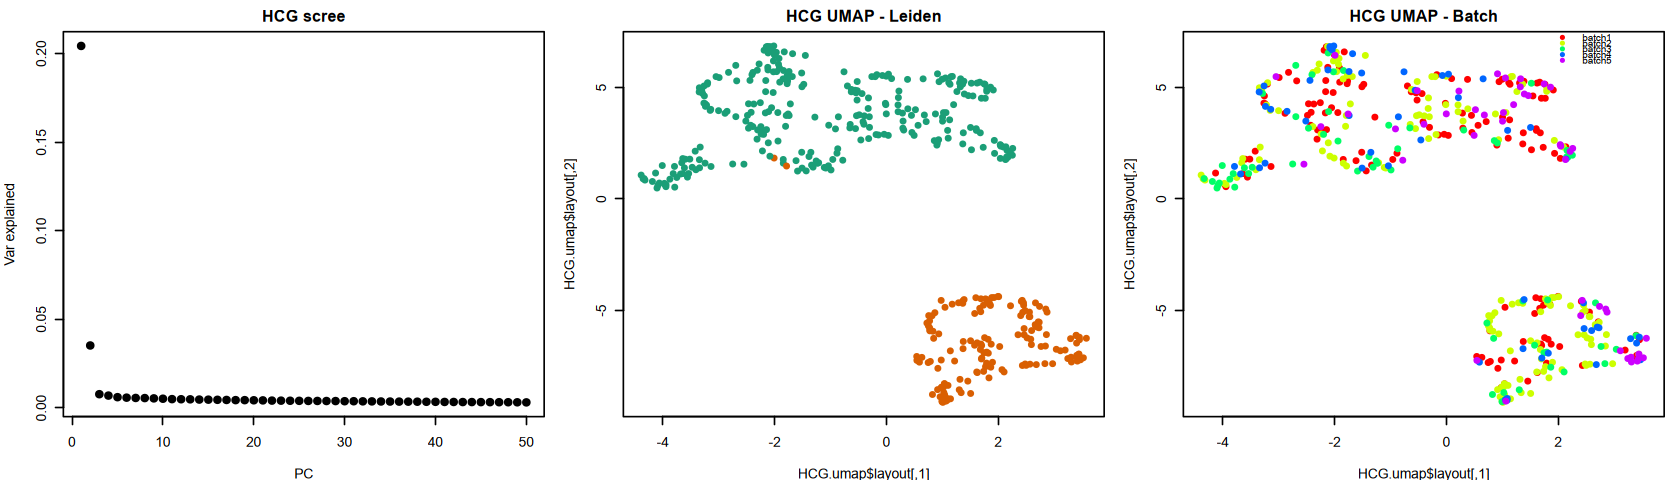

In [6]:
options(repr.plot.width = 14, repr.plot.height = 4)
# §4c HCG visualization
bfact <- as.factor(submetadata[rownames(HCG.umap$layout), "sample"])
par(mfrow = c(1, 3), mar = c(4, 4, 2, 1), bg = "white")
d <- HCG.svd_full$d
plot(d[1:50]^2 / sum(d^2), pch = 19, xlab = "PC", ylab = "Var explained", main = "HCG scree")
plot(HCG.umap$layout, col = partition_colors(HCG.part), pch = 16, main = "HCG UMAP - Leiden")
plot(HCG.umap$layout, col = rainbow(length(levels(bfact)))[bfact], pch = 16, main = "HCG UMAP - Batch")
legend("topright", legend = levels(bfact), col = rainbow(length(levels(bfact))), pch = 16, cex = 0.7, bty = "n")
dev.copy2pdf(file = file.path(OUT_FIG, "hcg.pdf"), width = 14, height = 4)

## §5 Hi-C — Harmony SVD clustering

Hi-C SVD from hicluster → Harmony batch correction → Leiden at resolution **0.10**,
knn_k = 25.

A sweep of 1210 configurations selected this setting: a clean 2-cluster split with
**ARI = 0.927** against the HCG clustering, against 0.857 for the previous
`n_pc = 9, res = 0.2`. Harmony and raw (uncorrected) embeddings tied at the top; Harmony
is kept for consistency with §6 and to suppress batch-driven noise. The sweep ran on the
earlier 380-cell cohort and is not part of this repository.


In [7]:
# §5a HiC: load + Harmony + Leiden on top-5 PCs (parameters from a sweep)
library(harmony)

hic_h5  <- file.path(WORKDIR, "06.hiccluster_snakemake",
                     "hicluster_250kb_embed_dir",
                     "all_merged.pad1_std1_rp0.5_sqrtvc.svd20.hdf5")
hic_ord <- file.path(WORKDIR, "06.hiccluster_snakemake",
                     "hicluster_250kb_chr1_impute_file_list.txt")
hic_mat <- t(h5read(hic_h5, "/data"))
ind     <- readLines(hic_ord)
ind     <- sub("_chr\\S+", "", sub("\\S+chr1/", "", ind, perl = TRUE), perl = TRUE)
stopifnot(length(ind) == nrow(hic_mat))
rownames(hic_mat) <- ind
common  <- intersect(rownames(hic_mat), submetadata$name)
hic_mat <- hic_mat[common, , drop = FALSE]
cat("HiC SVD (cells x PCs):", dim(hic_mat), "\n")

# Harmony batch correction
meta_h <- submetadata[rownames(hic_mat), , drop = FALSE]
set.seed(42)
hic_harmony <- suppressMessages(suppressWarnings(
  RunHarmony(hic_mat, meta_h, vars_use = "sample", verbose = FALSE)))

# UMAP + Leiden on the top 3 PCs of the Harmony-corrected embedding
# Chosen by a parameter sweep: ARI = 0.927 against the HCG clustering, versus
# 0.857 for the previous n_pc=9 / res=0.2 setting. Note the sweep was run on the
# earlier 380-cell cohort, before the doublet filter raised it to 441. The sweep
# itself is not part of this repository.
set.seed(42)
hic_umap <- umap(as.matrix(hic_harmony[, 1:5]))
hic_part <- run_leiden(hic_harmony, n_pc = 5, k = 25, resolution = 0.10)
names(hic_part) <- rownames(hic_harmony)
submetadata$hic_cluster <- NA_integer_
submetadata[rownames(hic_harmony), "hic_cluster"] <- hic_part
cat("HiC Leiden:\n"); print(table(hic_part))

write.table(hic_harmony,         file.path(OUT_TAB, "hic_embedding.txt"),         sep = "\t", quote = FALSE)
write.table(hic_harmony[, 1:7],  file.path(OUT_TAB, "hic_embedding_harmony.txt"), sep = "\t", quote = FALSE)
write.table(hic_umap$layout,     file.path(OUT_TAB, "hic_umap.txt"),              sep = "\t", quote = FALSE)
write.table(hic_umap$layout,     file.path(OUT_TAB, "hic_umap_harmony.txt"),      sep = "\t", quote = FALSE)


HiC SVD (cells x PCs): 441 20 
HiC Leiden:
hic_part
  1   2 
294 147 


pdf 
  2

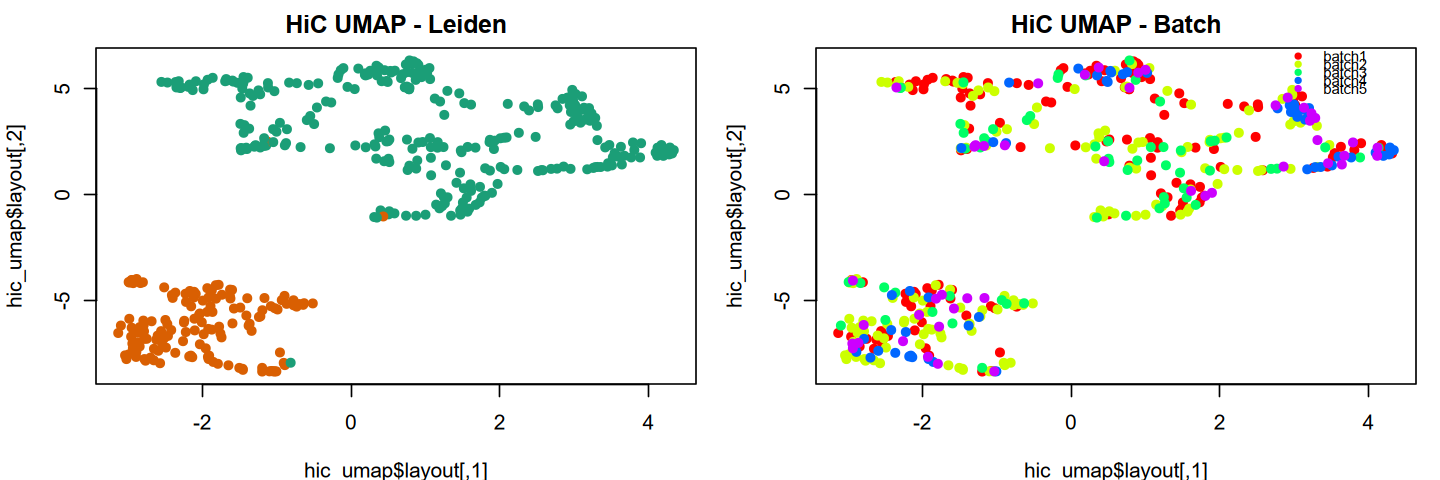

In [8]:
options(repr.plot.width = 12, repr.plot.height = 4)
# §5b HiC visualization
bfact <- as.factor(submetadata[rownames(hic_umap$layout), "sample"])
par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
plot(hic_umap$layout, col = partition_colors(hic_part), pch = 16, main = "HiC UMAP - Leiden")
plot(hic_umap$layout, col = rainbow(length(levels(bfact)))[bfact], pch = 16, main = "HiC UMAP - Batch")
legend("topright", legend = levels(bfact), col = rainbow(length(levels(bfact))), pch = 16, cex = 0.7, bty = "n")
dev.copy2pdf(file = file.path(OUT_FIG, "hic.pdf"), width = 12, height = 4)

## §6 GCH accessibility

Top-11547 variable bins → impute → SVD → Harmony → Leiden at `n_pc = 3`,
resolution **0.20**, knn_k = 25. UMAP on the same 3 PCs.

A sweep over `top_n × n_pc × knn_k × resolution` (2400 configurations) selected these
settings: a clean 2-cluster split at **ARI = 0.706**, NMI = 0.590 against HCG. The
previous `n_pc = 4, res = 0.30` landed on a 3-cluster attractor at ARI = 0.44 — Leiden
is RNG-sensitive at that resolution, so the lower value is also the more reproducible one.

The sweep grid is replayed inline so `build_emb(11547)` is a cache hit. That is what
keeps the Harmony output deterministic: Harmony has two stable attractors here depending
on the k-means initialisation.

**Separation quality:** silhouette 0.32 mean in the Harmony top-3 PCs (cluster 1: 0.26,
cluster 2: 0.44) — moderate, fuzzy at the boundary, 8.7 % of cells below zero. Agreement
with HCG is 92.4 %. This is expected rather than a clustering fault: GCH accessibility is
intrinsically less cell-type-discriminative than HCG methylation for GM12878 vs IMR90.
These statistics come from the 380-cell sweep cohort.


In [9]:
# §6a GCH: load + quantile normalize
gch_path <- file.path(WORKDIR, "QC", "methylation_matrices", "methylation_matrix_GCH_250kb.tsv.gz")
gch_mat <- read.table(gzfile(gch_path), header = TRUE, sep = "\t",
                      row.names = 1, check.names = FALSE,
                      na.strings = c("NA", "", "NaN"))
gch_mat <- data.matrix(gch_mat)
common  <- intersect(rownames(gch_mat), submetadata$name)
gch_mat <- gch_mat[common, , drop = FALSE]
gene_acc <- filter_high_na_genes(t(gch_mat), 0.5)   # bins x cells
cat("GCH after NA filter (bins x cells):", dim(gene_acc), "\n")

normalized_data <- quantile_normalize(as.matrix(gene_acc))

GCH after NA filter (bins x cells): 11547 441 


In [10]:
# §6b GCH: HVG top-11547 -> impute -> SVD
TOP_N <- 11547

bin_var  <- apply(normalized_data, 1, function(x) var(x, na.rm = TRUE))
bin_var[is.na(bin_var)] <- 0
keep_bin <- order(bin_var, decreasing = TRUE)[seq_len(min(TOP_N, length(bin_var)))]
sub_norm <- normalized_data[keep_bin, , drop = FALSE]

drop_cells <- colMeans(is.na(sub_norm)) > 0.8
if (any(drop_cells)) sub_norm <- sub_norm[, !drop_cells, drop = FALSE]
bin_na <- rowMeans(is.na(sub_norm))
if (any(bin_na > 0.8)) sub_norm <- sub_norm[bin_na <= 0.8, , drop = FALSE]
cat("GCH after HVG selection (bins x cells):", dim(sub_norm), "\n")

imp <- impute_relaxed(sub_norm, k = 10)
rownames(imp) <- rownames(sub_norm); colnames(imp) <- colnames(sub_norm)
gch_svd <- svd_embedding(imp, n_comps = 20)
cat("GCH SVD:", dim(gch_svd), "\n")

GCH after HVG selection (bins x cells): 11547 441 
GCH SVD: 441 20 


In [ ]:
# §6c GCH: cached Harmony embedding (sweep grid replayed for determinism)
set.seed(42)

emb_cache <- list()
build_emb_inline <- function(top_n) {
  key <- as.character(top_n)
  if (!is.null(emb_cache[[key]])) return(emb_cache[[key]])
  ord <- order(bin_var, decreasing = TRUE)
  sub_norm <- normalized_data[ord[seq_len(top_n)], , drop = FALSE]
  drop_cells <- colMeans(is.na(sub_norm)) > 0.8
  if (any(drop_cells)) sub_norm <- sub_norm[, !drop_cells, drop = FALSE]
  bin_na <- rowMeans(is.na(sub_norm))
  if (any(bin_na > 0.8)) sub_norm <- sub_norm[bin_na <= 0.8, , drop = FALSE]
  imp <- impute_relaxed(sub_norm, k = 10)
  rownames(imp) <- rownames(sub_norm); colnames(imp) <- colnames(sub_norm)
  n_comp <- min(20, nrow(imp) - 1, ncol(imp) - 1)
  emb <- svd_embedding(imp, n_comps = n_comp)
  meta_h <- submetadata[rownames(emb), , drop = FALSE]
  emb_h <- suppressMessages(suppressWarnings(
    RunHarmony(emb, meta_h, vars_use = "sample", verbose = FALSE)))
  emb_cache[[key]] <<- emb_h
  emb_h
}

# Replays the sweep grid so the build_emb(6400) Harmony call lands on the same
# RNG trajectory the chosen parameters came from. Harmony has two stable
# attractors here depending on the k-means initialisation, so without this
# replay the embedding is not reproducible.
TOP_NS_SWEEP <- c(800, 1600, 3200, 6400, 11547, nrow(normalized_data))
TOP_NS_SWEEP <- unique(TOP_NS_SWEEP[TOP_NS_SWEEP <= nrow(normalized_data)])
N_PCS_SWEEP  <- c(3, 4, 5, 6, 8, 10)
RES_SWEEP    <- c(0.1, 0.2, 0.3, 0.5, 1.0)
for (tn in TOP_NS_SWEEP) {
  emb_h <- build_emb_inline(tn)
  for (npc in N_PCS_SWEEP) {
    eff_npc <- min(npc, ncol(emb_h))
    for (res in RES_SWEEP) {
      p <- run_leiden(emb_h, n_pc = eff_npc, k = 25, resolution = res)
    }
  }
}

# Use the cached Harmony embedding for the chosen setting (top_n = 6400)
gch_harmony <- emb_cache[["11547"]]
n_pc_use   <- min(3, ncol(gch_harmony))   # sweep best: n_pc = 3 (was 4)

set.seed(42)
gch_part <- run_leiden(gch_harmony, n_pc = n_pc_use, k = 25, resolution = 0.20)   # sweep best: res = 0.20 (was 0.30)
names(gch_part) <- rownames(gch_harmony)
submetadata$gch_cluster <- NA_integer_
submetadata[rownames(gch_harmony), "gch_cluster"] <- gch_part
cat("GCH Leiden:\n"); print(table(gch_part))

# UMAP on the same n_pc PCs as the Leiden graph
gch_umap <- umap::umap(as.matrix(gch_harmony[, seq_len(n_pc_use), drop = FALSE]))

write.table(gch_harmony,     file.path(OUT_TAB, "gch_embedding_harmony.txt"), sep = "\t", quote = FALSE)
write.table(gch_umap$layout, file.path(OUT_TAB, "gch_umap.txt"),              sep = "\t", quote = FALSE)


GCH Leiden:
gch_part
  1   2 
269 172 


pdf 
  2

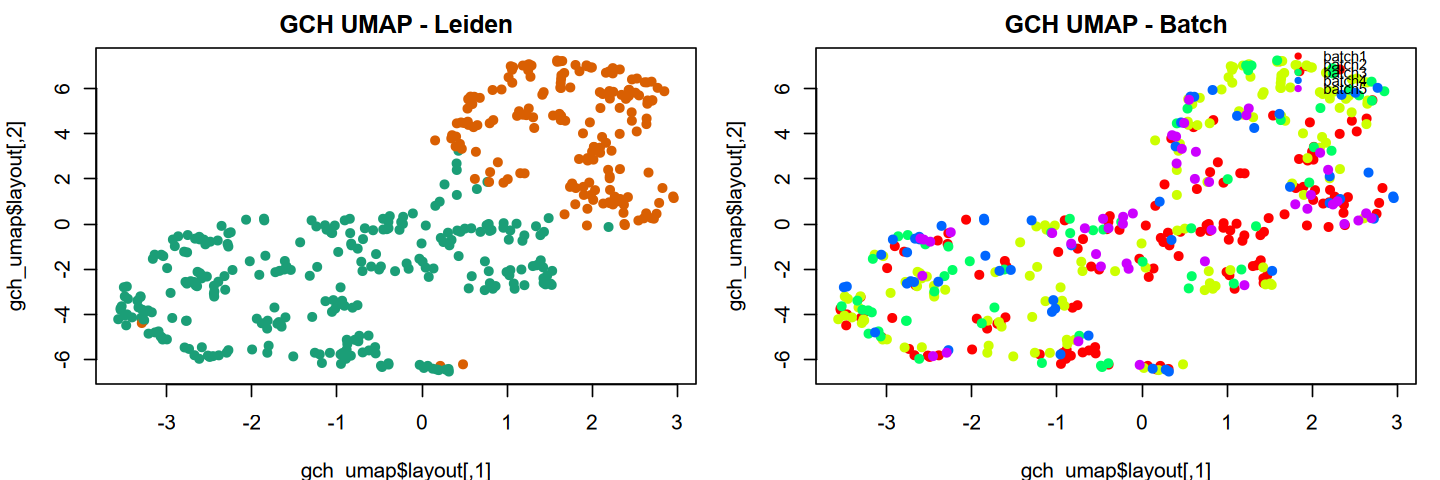

In [12]:
options(repr.plot.width = 12, repr.plot.height = 4)
# §6d GCH visualization
bfact <- as.factor(submetadata[rownames(gch_umap$layout), "sample"])
par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
plot(gch_umap$layout, col = partition_colors(gch_part), pch = 16, main = "GCH UMAP - Leiden")
plot(gch_umap$layout, col = rainbow(length(levels(bfact)))[bfact], pch = 16, main = "GCH UMAP - Batch")
legend("topright", legend = levels(bfact), col = rainbow(length(levels(bfact))), pch = 16, cex = 0.7, bty = "n")
dev.copy2pdf(file = file.path(OUT_FIG, "gch.pdf"), width = 12, height = 4)

## §7 Cell-type annotation

Per HCG (raw) cluster pseudobulk → Pearson correlation with the 250 kb bulk methylation
references for GM12878 and IMR90 → assign each cluster to the better-matching cell type.
Runs before §8, which assumes `submetadata$cell_type` is populated.


In [13]:
# §7a Load bulk references + parse HCG bin coords
gm  <- read.table(gzfile(file.path(PARENT, "bulk_methylation_GM12878.txt.gz")),
                  header = TRUE, sep = "\t", stringsAsFactors = FALSE)
imr <- read.table(gzfile(file.path(PARENT, "bulk_methylation_IMR90.txt.gz")),
                  header = TRUE, sep = "\t", stringsAsFactors = FALSE)
cat("Bulk GM12878:", nrow(gm), "  IMR90:", nrow(imr), "\n")

parse_bin <- function(x) {
  m <- regmatches(x, regexec("^(.+):(\\d+)-(\\d+)$", x))
  data.frame(bin = x,
             chr   = vapply(m, `[`, character(1), 2),
             start = as.integer(vapply(m, `[`, character(1), 3)),
             end   = as.integer(vapply(m, `[`, character(1), 4)),
             stringsAsFactors = FALSE)
}
bin_coords <- parse_bin(colnames(hcg_imputed))
key_cols   <- c("chr", "start", "end")
gm_m  <- merge(bin_coords, gm,  by = key_cols, sort = FALSE)
imr_m <- merge(bin_coords, imr, by = key_cols, sort = FALSE)
shared <- merge(gm_m[,  c("bin", key_cols, "methylation")],
                imr_m[, c("bin", key_cols, "methylation")],
                by = c("bin", key_cols), suffixes = c(".gm", ".imr"))
cat("Bins shared HCG + GM-bulk + IMR-bulk:", nrow(shared), "\n")

bulk_gm   <- shared$methylation.gm
bulk_imr  <- shared$methylation.imr
shared_bn <- shared$bin

Bulk GM12878: 10902   IMR90: 10902 
Bins shared HCG + GM-bulk + IMR-bulk: 10902 


In [14]:
# §7b Per-HCG-cluster pseudobulk -> correlate with bulk -> assign cell type
hcg_sub <- hcg_imputed[, shared_bn, drop = FALSE]
pseudo  <- list()
for (clu in sort(unique(submetadata$hcg_cluster))) {
  if (is.na(clu)) next
  cells <- rownames(hcg_sub)[submetadata[rownames(hcg_sub), "hcg_cluster"] == clu]
  pseudo[[as.character(clu)]] <- colMeans(hcg_sub[cells, , drop = FALSE], na.rm = TRUE)
}

cor_tab <- do.call(rbind, lapply(names(pseudo), function(k) {
  v <- pseudo[[k]]
  data.frame(cluster = k,
             cor_GM  = cor(v, bulk_gm,  use = "pairwise.complete.obs"),
             cor_IMR = cor(v, bulk_imr, use = "pairwise.complete.obs"),
             stringsAsFactors = FALSE)
}))
cor_tab$call <- ifelse(cor_tab$cor_GM > cor_tab$cor_IMR, "GM12878", "IMR90")
cat("\nCluster -> cell-type call:\n"); print(cor_tab, row.names = FALSE, digits = 3)

cluster_to_ct <- setNames(cor_tab$call, cor_tab$cluster)
submetadata$cell_type <- cluster_to_ct[as.character(submetadata$hcg_cluster)]
cat("\nFinal cell_type:\n"); print(table(submetadata$cell_type, useNA = "ifany"))

write.table(cor_tab, file.path(OUT_TAB, "cluster_to_celltype_correlations.tsv"),
            sep = "\t", quote = FALSE, row.names = FALSE)


Cluster -> cell-type call:
 cluster cor_GM cor_IMR    call
       1  0.927   0.482 GM12878
       2  0.592   0.895   IMR90

Final cell_type:

GM12878   IMR90 
    281     160 


## §8 Figures — per-modality UMAPs and annotation diagnostics

Four side-by-side UMAPs — HCG methylation, GCH accessibility, Hi-C chromatin structure,
and the joint embedding — every cell coloured by the `cell_type` annotation from §7, with
labels at each cell type's median position and a single shared legend. Layout follows
Fig. 4b of Chen et al., *Gene regulatory landscape dissected by single-cell four-omics
sequencing*. The remaining cells are annotation diagnostics: pseudobulk-vs-bulk scatter
and distributions, and the UMAPs recoloured by the final annotation.


Joint embedding (inline): cells in all 3 modalities: 441 
wrote figures/umap_fig4b_style.pdf (4 panels incl. joint)


Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label)):
“font family 'Arial' not found in PostScript font database”
Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label)):
“font family 'Arial' not found in PostScript font database”
Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label)):
“font family 'Arial' not found in PostScript font database”
Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label)):
“font family 'Arial' not found in PostScript font database”
Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label)):
“font family 'Arial' not found in PostScript font database”
Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label)):
“font family 'Arial' not found in PostScript font database”
Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label)):
“font family 'Arial' not found in PostScript font database”
Warning message in grid.Call(C_stringMetric, as.graphicsAnnot(x$label

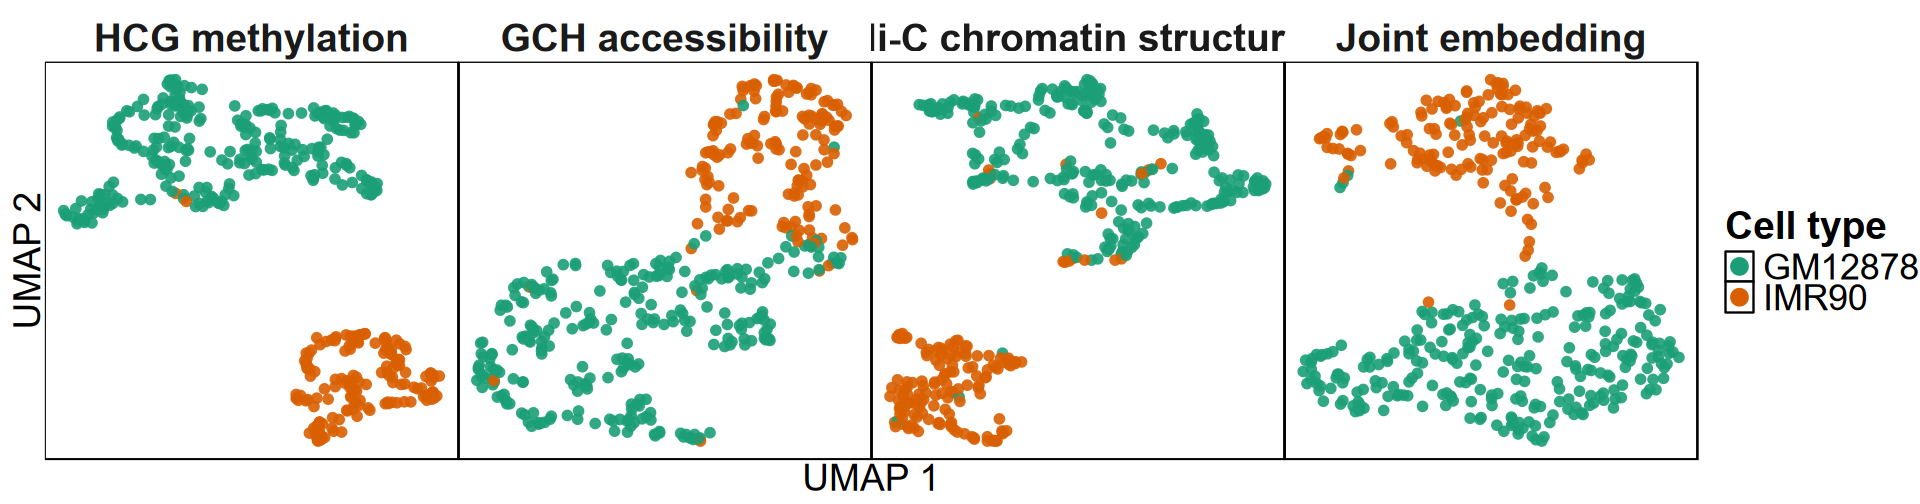

In [ ]:
options(repr.plot.width = 16, repr.plot.height = 4.2)

# §8a Four-panel per-modality UMAPs (Chen et al. 2026 Fig. 4b style)
# HCG / GCH / HiC / Joint. Cell type carried only in the legend (no overlaid
# text); axis tick values hidden; panels rendered side-by-side with no gap.

stopifnot("cell_type" %in% colnames(submetadata))
if (!exists("ct_palette")) ct_palette <- c("GM12878" = "#1B9E77", "IMR90" = "#D95F02")
# Make text substantially larger (publication level) and use Arial font
if (!exists("PUB_BASE"))   PUB_BASE   <- 20    # was 13
if (!exists("PUB_FONT"))   PUB_FONT   <- "Arial"

# ── Joint embedding ──────────────────────────────────────────────────────────
# Concatenates the three per-modality embeddings (HCG SVD, Hi-C Harmony, GCH
# Harmony) and runs UMAP on them; the four-panel figure below needs it. The
# exists() guard simply skips the work if you already built `joint_umap`
# yourself — nothing else in this notebook defines it.
if (!exists("joint_umap")) {
  stopifnot(exists("HCG.svd"), exists("hic_harmony"), exists("gch_harmony"))
  .hcg_emb <- HCG.svd[,     seq_len(5), drop = FALSE]   # raw SVD, top 5
  .hic_emb <- hic_harmony[, seq_len(7), drop = FALSE]   # Harmony, top 7
  .gch_emb <- gch_harmony[, seq_len(3), drop = FALSE]   # Harmony, top 3 (matches §6c)
  .shared  <- Reduce(intersect, list(rownames(.hcg_emb), rownames(.hic_emb),
                                     rownames(.gch_emb)))
  cat("Joint embedding (inline): cells in all 3 modalities:", length(.shared), "\n")
  .hcg_emb <- .hcg_emb[.shared, , drop = FALSE]
  .hic_emb <- .hic_emb[.shared, , drop = FALSE]
  .gch_emb <- .gch_emb[.shared, , drop = FALSE]
  # Z-score per column, concatenate features
  .joint_concat <- cbind(scale(.hcg_emb), scale(.hic_emb), scale(.gch_emb))
  colnames(.joint_concat) <- c(paste0("HCG", seq_len(ncol(.hcg_emb))),
                               paste0("HiC", seq_len(ncol(.hic_emb))),
                               paste0("GCH", seq_len(ncol(.gch_emb))))
  # PCA — keep all components (decorrelating rotation, not a dim reduction)
  .joint_pca <- prcomp(.joint_concat, center = FALSE, scale. = FALSE)$x
  # UMAP settings: n_neighbors = 10, min_dist = 0.2, euclidean, seed 42
  .ucfg <- umap::umap.defaults
  .ucfg$n_neighbors  <- 10
  .ucfg$min_dist     <- 0.2
  .ucfg$metric       <- "euclidean"
  .ucfg$random_state <- 42
  set.seed(42)
  joint_umap <- umap::umap(.joint_pca, config = .ucfg)
  rownames(joint_umap$layout) <- .shared
  if (exists("OUT_TAB")) {
    write.table(.joint_pca,        file.path(OUT_TAB, "joint_embedding.txt"),
                sep = "\t", quote = FALSE)
    write.table(joint_umap$layout, file.path(OUT_TAB, "joint_umap.txt"),
                sep = "\t", quote = FALSE)
  }
}

build_modality_df <- function(layout_mat, modality) {
  cells <- intersect(rownames(layout_mat), rownames(submetadata))
  data.frame(cell     = cells,
             UMAP1    = layout_mat[cells, 1],
             UMAP2    = layout_mat[cells, 2],
             cell_type= submetadata[cells, "cell_type"],
             modality = modality,
             stringsAsFactors = FALSE)
}
panels <- list(
  HCG   = build_modality_df(HCG.umap$layout,   "HCG methylation"),
  GCH   = build_modality_df(gch_umap$layout,   "GCH accessibility"),
  HiC   = build_modality_df(hic_umap$layout,   "3D Genome"),
  JOINT = build_modality_df(joint_umap$layout, "Joint embedding")
)
panel_levels <- vapply(panels, function(p) p$modality[1], character(1))
df_all <- do.call(rbind, panels)
df_all$modality <- factor(df_all$modality, levels = panel_levels)
df_all <- df_all[!is.na(df_all$cell_type), ]

fig4b_theme <- theme(
  panel.background = element_blank(), panel.grid = element_blank(),
  panel.border     = element_rect(colour = "black", fill = NA, linewidth = 0.6),
  axis.text        = element_blank(),     # no tick values on the box edges
  axis.ticks       = element_blank(),     # no tick marks either
  axis.title       = element_text(size = PUB_BASE + 2, family = PUB_FONT),
  strip.background = element_blank(),
  strip.text       = element_text(size = PUB_BASE + 3, face = "bold", family = PUB_FONT),
  legend.title     = element_text(size = PUB_BASE + 3, face = "bold", family = PUB_FONT),
  legend.text      = element_text(size = PUB_BASE + 1, family = PUB_FONT),
  legend.key       = element_rect(fill = "white"),
  legend.position  = "right",
  panel.spacing.x  = unit(0, "lines"),    # boxes touch — no horizontal gap
  plot.margin      = margin(8, 8, 8, 8)
)

p_fig4b <- ggplot(df_all, aes(UMAP1, UMAP2, colour = cell_type)) +
  geom_point(size = 3, alpha = 0.9, stroke = 0) +
  scale_color_manual(values = ct_palette, name = "Cell type") +
  facet_wrap(~ modality, nrow = 1, scales = "free") +
  labs(x = "UMAP 1", y = "UMAP 2") +
  fig4b_theme +
  guides(colour = guide_legend(override.aes = list(size = 5, alpha = 1)))

ggsave(file.path(OUT_FIG, "umap_fig4b_style.pdf"), p_fig4b,
       width = 16, height = 4.2, units = "in")
cat("wrote figures/umap_fig4b_style.pdf (4 panels incl. joint)\n")
p_fig4b


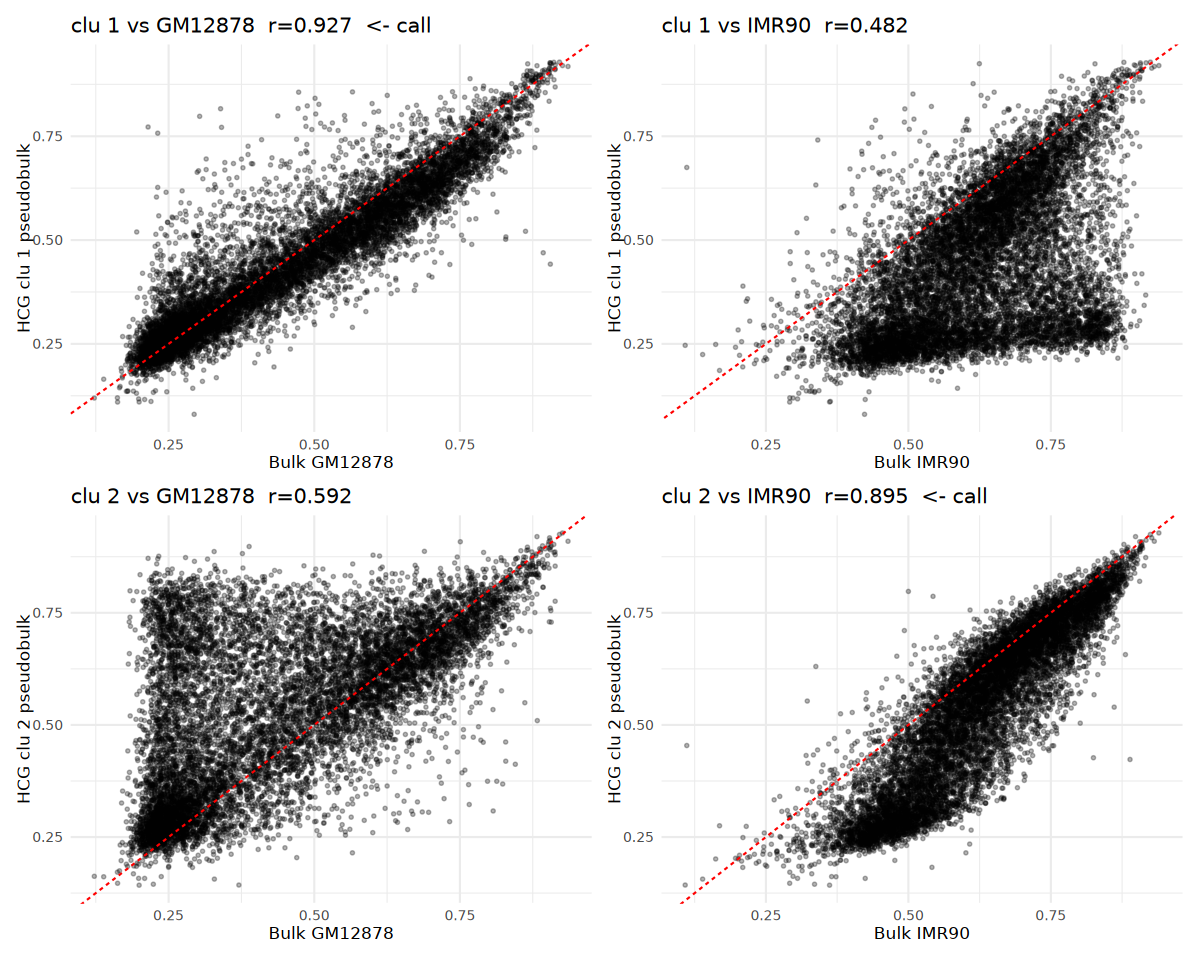

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 8)
# §8b Annotation plots: pseudobulk vs bulk scatter
ct_pal <- c("GM12878" = "#1B9E77", "IMR90" = "#D95F02")

panels <- list()
for (clu in names(pseudo)) {
  v <- pseudo[[clu]]; ok <- is.finite(v) & is.finite(bulk_gm) & is.finite(bulk_imr)
  d1 <- data.frame(x = bulk_gm[ok],  y = v[ok])
  d2 <- data.frame(x = bulk_imr[ok], y = v[ok])
  r1 <- cor(d1$x, d1$y); r2 <- cor(d2$x, d2$y); call_ <- cluster_to_ct[clu]
  p1 <- ggplot(d1, aes(x, y)) + geom_point(alpha = 0.3, size = 0.6) +
        geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "red") +
        labs(x = "Bulk GM12878", y = sprintf("HCG clu %s pseudobulk", clu),
             title = sprintf("clu %s vs GM12878  r=%.3f%s", clu, r1,
                             ifelse(call_ == "GM12878", "  <- call", ""))) +
        theme_minimal(base_size = 10)
  p2 <- ggplot(d2, aes(x, y)) + geom_point(alpha = 0.3, size = 0.6) +
        geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "red") +
        labs(x = "Bulk IMR90", y = sprintf("HCG clu %s pseudobulk", clu),
             title = sprintf("clu %s vs IMR90  r=%.3f%s", clu, r2,
                             ifelse(call_ == "IMR90", "  <- call", ""))) +
        theme_minimal(base_size = 10)
  panels[[clu]] <- p1 | p2
}
scat <- Reduce(`/`, panels)
ggsave(file.path(OUT_FIG, "annotation_pseudobulk_vs_bulk_scatter.pdf"),
       scat, width = 10, height = 4 * length(panels))
scat

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


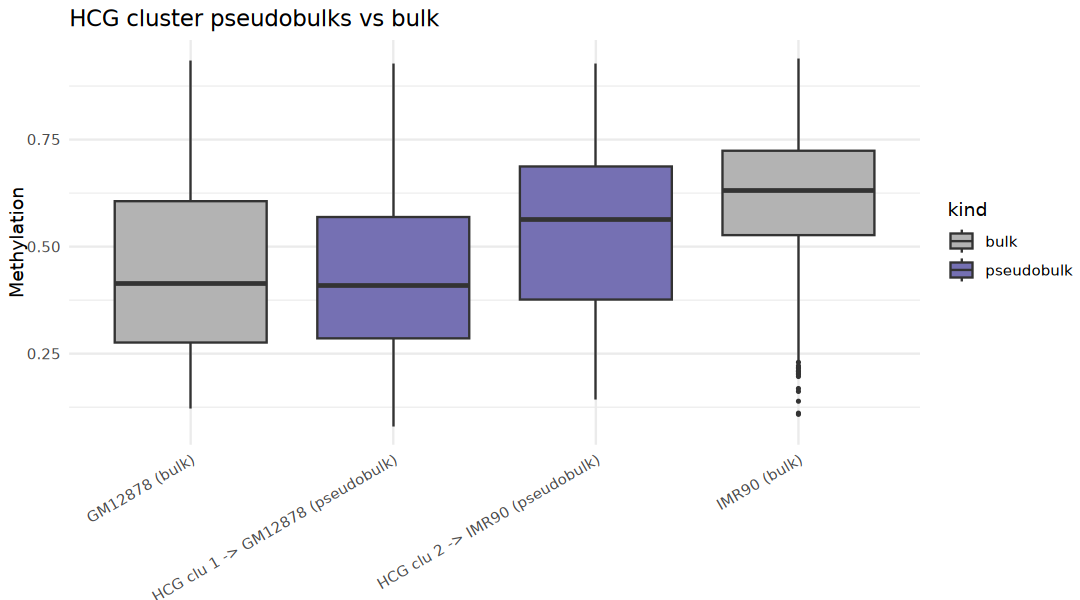

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 5)
# §8c Annotation plots: pseudobulk vs bulk distributions
boxes <- bind_rows(
  data.frame(value = bulk_gm,  group = "GM12878 (bulk)", kind = "bulk"),
  data.frame(value = bulk_imr, group = "IMR90 (bulk)",   kind = "bulk"),
  do.call(rbind, lapply(names(pseudo), function(k)
    data.frame(value = pseudo[[k]],
               group = sprintf("HCG clu %s -> %s (pseudobulk)", k, cluster_to_ct[k]),
               kind = "pseudobulk")))
)
p_box <- ggplot(boxes, aes(x = group, y = value, fill = kind)) +
  geom_boxplot(outlier.size = 0.4) +
  scale_fill_manual(values = c("bulk" = "gray70", "pseudobulk" = "#7570B3")) +
  labs(x = NULL, y = "Methylation", title = "HCG cluster pseudobulks vs bulk") +
  theme_minimal(base_size = 11) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
ggsave(file.path(OUT_FIG, "annotation_boxplot.pdf"), p_box, width = 9, height = 5)
p_box

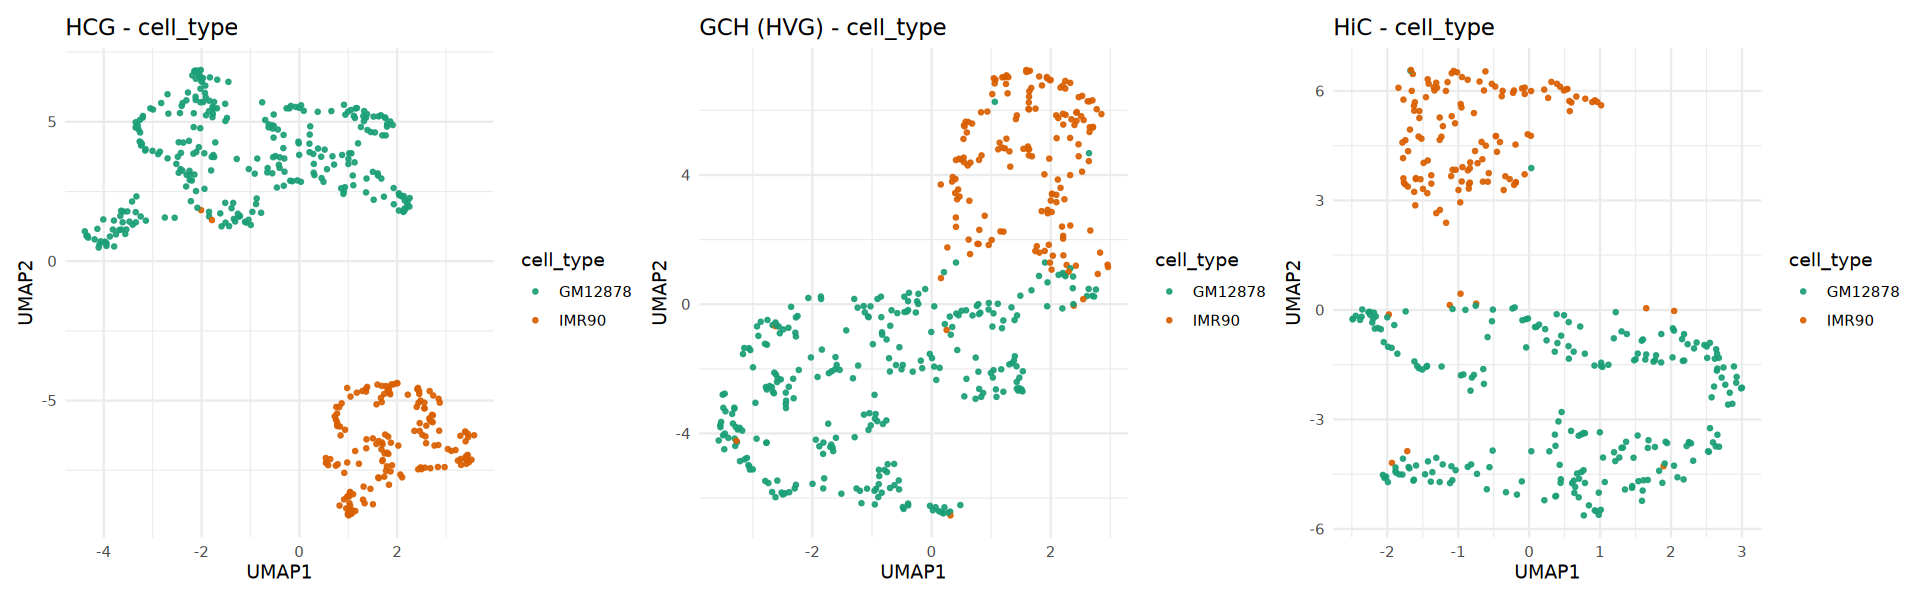

In [ ]:
options(repr.plot.width = 16, repr.plot.height = 5)
# §8d UMAPs coloured by the final cell_type annotation
df_hcg_ct <- make_umap_df(HCG.umap$layout, submetadata) %>% filter(!is.na(cell_type))
df_gch_ct <- make_umap_df(gch_umap$layout, submetadata) %>% filter(!is.na(cell_type))
df_hic_ct <- make_umap_df(hic_umap$layout, submetadata) %>% filter(!is.na(cell_type))
mk_ct <- function(df, title) ggplot(df, aes(UMAP1, UMAP2, colour = cell_type)) +
  geom_point(size = 0.8, alpha = 0.9) +
  scale_color_manual(values = ct_pal) +
  ggtitle(title) + theme_minimal(base_size = 11) + theme(legend.position = "right")
ct_panel <- mk_ct(df_hcg_ct, "HCG - cell_type") |
            mk_ct(df_gch_ct, "GCH (HVG) - cell_type") |
            mk_ct(df_hic_ct, "HiC - cell_type")
ggsave(file.path(OUT_FIG, "annotation_umaps_celltype.pdf"),
       ct_panel, width = 16, height = 5)
ct_panel

## §9 Save final outputs

In [ ]:
# §9 Save final outputs
gm_cells  <- rownames(submetadata)[submetadata$cell_type == "GM12878" & !is.na(submetadata$cell_type)]
imr_cells <- rownames(submetadata)[submetadata$cell_type == "IMR90"   & !is.na(submetadata$cell_type)]
writeLines(gm_cells,  file.path(ANN_DIR, "gm12878_cells.txt"))
writeLines(imr_cells, file.path(ANN_DIR, "imr90_cells.txt"))

# Per-cell colour (matches ct_palette used across the §8 figures; Dark2 first two,
# grey80 for unlabeled cells as in the joint-UMAP na.value)
if (!exists("ct_palette")) ct_palette <- c("GM12878" = "#1B9E77", "IMR90" = "#D95F02")
ct_color <- function(x) ifelse(is.na(x) | !(x %in% names(ct_palette)),
                               "grey80", ct_palette[x])
submetadata$cell_type_color <- unname(ct_color(submetadata$cell_type))

# cell -> cell_type (+ colour) mapping (only labeled cells)
ct_tbl <- data.frame(
  cell            = rownames(submetadata),
  cell_type       = submetadata$cell_type,
  cell_type_color = submetadata$cell_type_color,
  stringsAsFactors = FALSE
)
ct_tbl <- ct_tbl[!is.na(ct_tbl$cell_type), , drop = FALSE]
write.table(ct_tbl, file.path(ANN_DIR, "cell_type_table.tsv"),
            sep = "\t", quote = FALSE, row.names = FALSE)

# Full metadata with cell_type column (all QC-passed cells; cell_type may be NA)
write.table(submetadata,
            file.path(ANN_DIR, "metadata_with_cell_type.txt"),
            sep = "\t", quote = FALSE, row.names = FALSE)

cat(sprintf("GM12878: %d cells\nIMR90:   %d cells\nLabeled: %d / %d\n",
            length(gm_cells), length(imr_cells),
            length(gm_cells) + length(imr_cells), nrow(submetadata)))
cat("\nWritten to:\n  ", ANN_DIR, "\n",
    "  - gm12878_cells.txt        (one cell-id per line)\n",
    "  - imr90_cells.txt          (one cell-id per line)\n",
    "  - cell_type_table.tsv      (cell<TAB>cell_type<TAB>cell_type_color, labeled only)\n",
    "  - metadata_with_cell_type.txt   (full submetadata)\n",
    sep = "")
cat("\nTables: ", OUT_TAB, "\nFigures:", OUT_FIG, "\n")

GM12878: 281 cells
IMR90:   160 cells
Labeled: 441 / 441

Written to:
  /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/subset_clustering/250kb/annotation
  - gm12878_cells.txt        (one cell-id per line)
  - imr90_cells.txt          (one cell-id per line)
  - cell_type_table.tsv      (cell<TAB>cell_type, labeled only)
  - metadata_with_cell_type.txt   (full submetadata)

Tables:  /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/subset_clustering/250kb/tables 
Figures: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/subset_clustering/250kb/figures 
